# 第 07 关：构造五因子

**本关要回答的问题：** Fama 和 French（2015，下称 FF2015）为什么在三因子之外加入**盈利**和**投资**？这两个新因子怎样从公司特征变成收益序列？

### 经济动机：从估值方程出发
股票的价格等于未来分给股东的现金流的折现值。FF2015 把这个关系写成按账面权益标准化的形式：

$$
\frac{M_t}{B_t}=\frac{\sum_{\tau=1}^{\infty}E\!\left(Y_{t+\tau}-dB_{t+\tau}\right)/(1+r)^{\tau}}{B_t}.
$$

- $M_t$：时点 $t$ 的股票市值；$B_t$：账面权益。左边是市值与账面权益之比，即 B/M 的倒数。
- $Y_{t+\tau}$：未来第 $\tau$ 期的盈利；$dB_{t+\tau}$：该期账面权益的增加，也就是公司把盈利留下来再投资的部分。$Y-dB$ 是可以分给股东的现金流。
- $r$：使等式成立的折现率，可以近似理解为股票的长期预期收益率。

固定其他量、只改变一个，可以读出三条预测：
1. **价值**：盈利和投资不变时，市值 $M_t$ 越低（B/M 越高），$r$ 越高。这是 HML 的动机。
2. **盈利**：B/M 和投资不变时，预期盈利 $Y$ 越高，$r$ 越高。直觉：同样的价格买到了更多利润，只有折现率更高，价格才对得上。
3. **投资**：B/M 和盈利不变时，预期投资 $dB$ 越高，$r$ 越低。直觉：同样的盈利要拿出更多去再投资，留给股东的现金流少了，价格却没变，说明折现率更低。

"其他量不变"这个前提很关键：一家高盈利公司如果股价已经很高（B/M 低），不一定有高预期收益。这也是为什么每个因子都在控制规模的同时按单一特征排序构造。这个方程告诉我们预期收益应当与哪些特征相关，但没有说明原因是风险还是定价偏差。

### 两个新特征，两个新因子
- **经营盈利能力 OP**（Operating Profitability）：（营业收入 − 销售成本 − 销售及管理费用 − 利息费用）÷ 账面权益，衡量每单位账面权益创造的经营利润。
- **投资 Inv**（Investment）：总资产的年增长率 =（上一财年总资产 − 再前一财年总资产）÷ 再前一财年总资产，衡量公司的扩张速度。
- **RMW（Robust Minus Weak）**：高盈利组合收益 − 低盈利组合收益。
- **CMA（Conservative Minus Aggressive）**：低投资（保守）组合收益 − 高投资（激进）组合收益。注意方向：做多的是**投资少**的公司，因为估值方程预测它们的预期收益更高。

本关用 French 公布的三套六组合收益重建这些因子，并与官方序列核对。

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "course.py").exists()), None)
if ROOT is None:
    raise RuntimeError("请在 asset_pricing_quest 项目或其 notebooks 文件夹中启动 Notebook。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from course import load_returns, style, save_table, paper_note, build_ff5
from analysis import fit_models, model_summary

style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 24)

In [2]:
display(Markdown(paper_note("ff2015")))

**论文对照：** [Fama & French (2015), A five-factor asset pricing model](../papers/ff2015_primary_reference.pdf)。准确表号、PDF 页码和复现范围见 [论文表格导航](../papers/TABLE_GUIDE.md)。当前数据版本会与原文历史版本存在差异。

## 1. 认识原材料：三套 2×3 组合
与第 04 关的 B/M 六组合一样，French 每年 6 月还按"规模 × OP"和"规模 × Inv"各形成六个组合：规模按 NYSE 中位数分小、大两组，特征按 NYSE 第 30、70 百分位分低、中、高三组，组内按市值加权。下面加载的是这些组合**已经实现的月收益**。三套组合的列顺序相同：先三个小盘，再三个大盘，特征从低到高。

一个版本细节：FF2015 论文中 OP 的分母是账面权益 BE；French 自 2018 年起改为 BE 加少数股东权益（合并报表中属于子公司其他股东的权益），并据此修订了历史数据。我们下载的是修订后的版本。[官方因子定义](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/f-f_5_factors_2x3.html)

In [3]:
START, END = "1963-07", "2013-12"
bm6 = load_returns("bm6", START, END)
op6 = load_returns("op6", START, END)
inv6 = load_returns("inv6", START, END)
for name, frame in [("B/M 六组合", bm6), ("OP 六组合", op6), ("Inv 六组合", inv6)]:
    display(Markdown(f"**{name}：** {frame.shape[0]} 个月，{frame.shape[1]} 个组合"))
    display(frame.head(2))

**B/M 六组合：** 606 个月，6 个组合

,SMALL LoBM,ME1 BM2,SMALL HiBM,BIG LoBM,ME2 BM2,BIG HiBM
month,,,,,,
1963-07,-0.0108,-0.0065,-0.0117,-0.0004,0.0049,-0.0162
1963-08,0.0445,0.0446,0.0582,0.0541,0.0469,0.0748


**OP 六组合：** 606 个月，6 个组合

,SMALL LoOP,ME1 OP2,SMALL HiOP,BIG LoOP,ME2 OP2,BIG HiOP
month,,,,,,
1963-07,-0.0083,-0.0060,-0.0047,-0.0088,0.0041,0.0004
1963-08,0.0483,0.0429,0.0534,0.0556,0.0493,0.0585


**Inv 六组合：** 606 个月，6 个组合

,SMALL LoINV,ME1 INV2,SMALL HiINV,BIG LoINV,ME2 INV2,BIG HiINV
month,,,,,,
1963-07,-0.0100,-0.0051,-0.0014,-0.0124,0.0055,0.0020
1963-08,0.0464,0.0442,0.0554,0.0618,0.0483,0.0606


## 2. 按公式加减组合收益
用 $S$、$B$ 表示小、大规模；$R$、$W$ 表示高（Robust）、低（Weak）盈利；$C$、$A$ 表示低（Conservative）、高（Aggressive）投资。两个新因子都是"两个规模组的平均"相减：

$$
RMW=\tfrac12(S_R+B_R)-\tfrac12(S_W+B_W),\qquad
CMA=\tfrac12(S_C+B_C)-\tfrac12(S_A+B_A).
$$

**五因子的 SMB 与三因子不同**：它对三套六组合各算一次"三个小盘的平均 − 三个大盘的平均"，再把三个结果平均。这样规模因子在 B/M、盈利、投资三个维度上都做了平衡。

代码实现在 `src/course.py` 的 `build_ff5` 中，下面先打印源码方便对照：`small_big` 计算规模差；`high_low` 计算（位置 2 + 位置 5）/2 −（位置 0 + 位置 3）/2，即高特征减低特征。CMA 前面有负号，因为 Inv 组合按投资从低到高排列，而 CMA 要的是低减高。最后一张表是重建因子的前 3 个月（单位 %）。

In [4]:
import inspect
print(inspect.getsource(build_ff5))
constructed = build_ff5().loc[START:END, ["SMB", "HML", "RMW", "CMA"]]
official = load_returns("ff5", START, END)
assert constructed.index.equals(official.index)
display((constructed.head(3)*100).rename_axis("月；数值单位 %"))

def build_ff5():
    """从三套六组合构造 FF5 的四个非市场因子。"""
    a, b, c = [load_returns(k) for k in ('bm6', 'op6', 'inv6')]
    dates = a.index.intersection(b.index).intersection(c.index)
    a, b, c = [x.loc[dates] for x in (a, b, c)]
    if any(x.shape[1] != 6 or x.isna().any().any() for x in (a, b, c)):
        raise ValueError('六组合结构或数据完整性不符合预期。')
    small_big = lambda p: p.iloc[:, :3].mean(axis=1) - p.iloc[:, 3:].mean(axis=1)
    high_low = lambda p: (p.iloc[:, 2] + p.iloc[:, 5] - p.iloc[:, 0] - p.iloc[:, 3]) / 2
    return pd.DataFrame({'SMB': (small_big(a) + small_big(b) + small_big(c)) / 3,
                         'HML': high_low(a), 'RMW': high_low(b), 'CMA': -high_low(c)})



,SMB,HML,RMW,CMA
月；数值单位 %,,,,
1963-07,-0.4837,-0.8352,0.6399,-1.1477
1963-08,-0.8002,1.7174,0.3979,-0.3845
1963-09,-0.4282,-0.0191,-0.7754,0.1492


## 3. 与官方序列逐月核对
误差用 **bp（基点）/月**表示：1 bp = 0.01 个百分点 = 小数 0.0001。官方因子文件只保留两位小数（百分数），所以单月的舍入误差最多 0.5 bp。核对看两件事：平均误差是否接近零（没有系统偏差）；最大误差是否不超过舍入精度。

表中各列：`mean_error_bp` 平均误差，`mean_abs_error_bp` 平均绝对误差，`max_abs_error_bp` 单月最大绝对误差，`correlation` 相关系数。

,mean_error_bp,mean_abs_error_bp,max_abs_error_bp,correlation
SMB,0.0029,0.2411,0.4989,1.0
HML,0.0126,0.2504,0.5000,1.0
RMW,0.0142,0.2529,0.5000,1.0
CMA,-0.0122,0.2482,0.5000,1.0


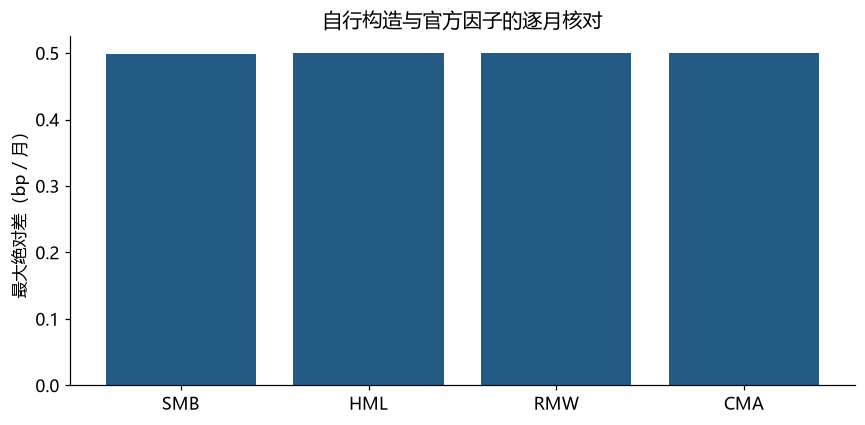

In [5]:
factor_names = ["SMB", "HML", "RMW", "CMA"]
errors_bp = (constructed - official[factor_names])*10000
comparison = pd.DataFrame({
    "mean_error_bp": errors_bp.mean(),
    "mean_abs_error_bp": errors_bp.abs().mean(),
    "max_abs_error_bp": errors_bp.abs().max(),
    "correlation": pd.Series({name: constructed[name].corr(official[name]) for name in factor_names}),
})
display(comparison.round(5))
save_table(comparison, "07_ff5_reconstruction_check")
save_table(constructed, "07_constructed_ff5_nonmarket_factors")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(comparison.index, comparison["max_abs_error_bp"], color="#245b84")
ax.set_ylabel("最大绝对差（bp / 月）")
ax.set_title("自行构造与官方因子的逐月核对")
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

In [6]:
worst = comparison["max_abs_error_bp"].idxmax()
display(Markdown(
    f"四个因子的单月最大误差都不超过 **{comparison.loc[worst, 'max_abs_error_bp']:.4f} bp**，"
    "平均误差接近零，正好在官方文件两位小数的舍入范围内：我们用公开的六组合完全重建了五因子中的四个非市场因子。"
    "如果差异明显超过 0.5 bp，应依次检查月份是否对齐、列的顺序、多空方向（例如 CMA 的负号）和数据版本。"))

四个因子的单月最大误差都不超过 **0.5000 bp**，平均误差接近零，正好在官方文件两位小数的舍入范围内：我们用公开的六组合完全重建了五因子中的四个非市场因子。如果差异明显超过 0.5 bp，应依次检查月份是否对齐、列的顺序、多空方向（例如 CMA 的负号）和数据版本。

## 4. 同名的 SMB，两种构造
三因子文件的 SMB 只来自规模×B/M 六组合；五因子文件的 SMB 来自三套六组合的平均。名字一样，序列不同。下面在相同月份上比较两者。

这对下一关很重要：拿"官方三因子"和"官方五因子"比较时，变化的不只是多了 RMW 和 CMA，SMB 本身也换了。想单独看新增两个因子的贡献，应该从五因子文件中取前三个因子作为三因子模型。

In [7]:
ff3 = load_returns("ff3", START, END)
smb_check = pd.DataFrame({"SMB_FF3": ff3["SMB"], "SMB_FF5": official["SMB"]})
smb_diagnostic = pd.Series({
    "correlation": smb_check.corr().iloc[0, 1],
    "mean_FF3_pct_month": smb_check["SMB_FF3"].mean()*100,
    "mean_FF5_pct_month": smb_check["SMB_FF5"].mean()*100,
    "mean_abs_difference_bp": smb_check.diff(axis=1).iloc[:, 1].abs().mean()*10000,
}, name="当前数据口径")
display(smb_diagnostic.to_frame().round(4))
save_table(smb_diagnostic.to_frame(), "07_smb_definition_comparison")

,当前数据口径
correlation,0.9845
mean_FF3_pct_month,0.2298
mean_FF5_pct_month,0.2796
mean_abs_difference_bp,32.5594


WindowsPath('E:/Eth data/asset_pricing_quest/results/07_smb_definition_comparison.csv')

**怎么读：** 两种 SMB 的相关系数约 0.98，平均每月相差约 33 bp（0.33 个百分点），五因子版本的均值略高（0.28 对 0.23 %/月）。两者高度相关，但并不相同。

## 5. 因子的平均收益
因子的月收益是"多头组合 − 空头组合"。均值为正，表示历史上多头一侧平均跑赢空头一侧，这是用它来解释平均收益的前提。下表报告 1963-07 至 2013-12 的月均收益（`mean_pct_month`）、标准差（`sd_pct_month`）和 HAC t 值（`t_mean_hac`，6 阶滞后）。

In [8]:
rows = []
for name in factor_names:
    fit = sm.OLS(official[name].to_numpy(dtype=float), np.ones((len(official), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": 6, "use_correction": True})
    rows.append({"factor": name, "mean_pct_month": official[name].mean()*100,
                 "sd_pct_month": official[name].std(ddof=1)*100,
                 "t_mean_hac": float(fit.tvalues[0])})
factor_summary = pd.DataFrame(rows).set_index("factor")
display(factor_summary.round(4))
save_table(factor_summary, "07_factor_summary")

,mean_pct_month,sd_pct_month,t_mean_hac
factor,,,
SMB,0.2796,3.0464,2.1158
HML,0.3816,2.7928,2.8282
RMW,0.2681,2.2485,2.5683
CMA,0.3244,2.0002,3.4846


WindowsPath('E:/Eth data/asset_pricing_quest/results/07_factor_summary.csv')

**怎么读：** 四个因子的平均收益都在 0.27–0.38 %/月之间，HAC t 值都大于 2。CMA 的标准差最小而 t 值最高：低投资减高投资这条收益序列相当稳定。

## 6. 与原文 Table 4 对照
原文 Table 4 报告了 2×3 因子的月均收益（[打开原文第 7 页](../papers/ff2015_primary_reference.pdf#page=7)）。`paper_pct_month` 是原文数值（两位小数），`current_pct_month` 是用当前数据算出的值，`current_minus_paper_pp` 是两者之差（个百分点）。差异都在 0.02 个百分点以内，来自数据修订和 OP 定义的更新。

In [9]:
import json
paper_map = json.loads((ROOT / "papers" / "paper_map.json").read_text(encoding="utf-8"))
factor_anchors = [a for a in paper_map["numeric_anchors"]
                  if a["paper"] == "ff2015" and a["table"] == "4"
                  and a["metric"] == "mean_factor_return"]
anchor_rows = []
for anchor in factor_anchors:
    current = official[anchor["key"]].mean()*100
    anchor_rows.append({"factor": anchor["key"], "paper_pct_month": anchor["paper_value"],
                        "current_pct_month": current,
                        "current_minus_paper_pp": current-anchor["paper_value"]})
factor_paper_comparison = pd.DataFrame(anchor_rows).set_index("factor")
display(factor_paper_comparison.round(4))
save_table(factor_paper_comparison, "07_table4_paper_comparison")

,paper_pct_month,current_pct_month,current_minus_paper_pp
factor,,,
Mkt-RF,0.50,0.5010,0.0010
SMB,0.29,0.2796,-0.0104
HML,0.37,0.3816,0.0116
RMW,0.25,0.2681,0.0181
CMA,0.33,0.3244,-0.0056


WindowsPath('E:/Eth data/asset_pricing_quest/results/07_table4_paper_comparison.csv')

## 通关证据与 Boss 作答区

提交：构造公式与代码的对应关系、因子误差表、两种 SMB 的比较。

**Boss：** 如果有人把经典三因子文件直接拼上 RMW 和 CMA 两列，当作"五因子模型"，你会要求他提供哪些证据，来说明这个模型和标准五因子模型的关系？

**你的回答：**

（留空，运行与思考后填写。）